## Fire Hazard Share by ZIP Code
Combine CAL FIRE's SRA (2024) and LRA (2025) Fire Hazard Severity Zones, keep High and Very High, and calculate the share of each ZIP code's land in those zones

In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd

raw = Path("../data/raw")
clean = Path("../data/clean")

In [2]:
sra_path = raw / "FHSZSRA_23_3/FHSZSRA_23_3.gdb"
lra_path = raw / "FHSZLRA251Allgdb/FHSZLRA25_1_All.gdb"

sra = gpd.read_file(sra_path, layer="FHSZSRA_23_3")
lra = gpd.read_file(lra_path, layer="FHSALRA25_v1_All")

c:\Users\shane\Downloads\Projects\wildfire_insurance\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(


In [3]:
print(sra.crs)
print(len(sra))
sra.head()

EPSG:3310
18423


,SRA,FHSZ,FHSZ_Description,Shape_Length,Shape_Area,geometry
0,SRA,1,Moderate,172.429380,1.572066e+03,"MULTIPOLYGON Z (((288964.702 -601800 0, 288962..."
1,SRA,1,Moderate,543.383043,6.692750e+03,"MULTIPOLYGON Z (((288961.993 -601710 0, 288961..."
2,SRA,1,Moderate,73.264096,1.987903e+02,"MULTIPOLYGON Z (((288953.826 -601440 0, 288953..."
3,SRA,1,Moderate,1766.175581,7.094115e+04,"MULTIPOLYGON Z (((287010 -600286.871 0, 286956..."
4,SRA,1,Moderate,11101.130614,1.348545e+06,"MULTIPOLYGON Z (((288950.227 -601320 0, 288950..."


In [4]:
print(lra.crs)
print(len(lra))
lra.head()

EPSG:3310
9752


,SRA,FHSZ,FHSZ_Description,Shape_Length,Shape_Area,geometry
0,LRA,-3,NonWildland,2781.759086,1.568475e+05,"MULTIPOLYGON (((271020 -604422.652, 270940.566..."
1,LRA,-3,NonWildland,2327.045466,1.758934e+05,"MULTIPOLYGON (((270480 -603390, 270480 -603360..."
2,LRA,-3,NonWildland,29612.610679,8.974583e+06,"MULTIPOLYGON (((286479.276 -600180, 286479.327..."
3,LRA,-3,NonWildland,2640.000000,2.295000e+05,"MULTIPOLYGON (((280050 -599490, 280050 -599550..."
4,LRA,-3,NonWildland,56.903253,1.050744e+00,"MULTIPOLYGON (((269649.996 -598836.931, 269621..."


In [5]:
sra.groupby(["FHSZ", "FHSZ_Description"]).size()

FHSZ  FHSZ_Description
1     Moderate            4188
2     High                5824
3     Very High           8411
dtype: int64

In [6]:
lra.groupby(["FHSZ", "FHSZ_Description"]).size()

FHSZ  FHSZ_Description
-3    NonWildland         1954
 1    Moderate            4741
 2    High                2049
 3    Very High           1008
dtype: int64

Both layers are already in EPSG:3310, we were planning on using this coordinate system. Hazard layers dont need to get projected again, the ZIP code boundaries will need to be reprojected. FHSZ match in both files, while LRA has -3 NonWildland, which is unzoned city land. SRA geometry has Z values (elevation) that we have to remove, so the two layers combine cleanly.

In [7]:
#removing the Z values from the SRA
sra["geometry"] = sra.geometry.force_2d()
print(sra.geometry.has_z.any(), lra.geometry.has_z.any())

False False


In [8]:
#combine layers, we want to keep High and Very High
hazard = pd.concat([sra, lra], ignore_index = True)
high = hazard[hazard["FHSZ"].isin([2, 3])].copy()

print(len(hazard), len(high))
high["FHSZ_Description"].value_counts()

28175 17292


FHSZ_Description
Very High    9419
High         7873
Name: count, dtype: int64

In [9]:
#check that the shapes are valid
print(f"Valid shapes: {high.is_valid.mean():.2%}")
high["geometry"] = high.geometry.make_valid()
print(f"After fix: {high.is_valid.mean():.2%}")

Valid shapes: 98.61%
After fix: 100.00%


In [10]:
#merge shapes by hazard class to prevent double-counting and leave only what we need
high_zones = high.dissolve(by = "FHSZ_Description").reset_index()
high_zones[["FHSZ_Description", "geometry"]]

,FHSZ_Description,geometry
0,High,"MULTIPOLYGON (((-289616.421 75210, -289620 752..."
1,Very High,"MULTIPOLYGON (((-309810 97740, -309810 97710, ..."


We removed the Z values, matched the counts, and found 1.39% of the shapes are invalid where make_valid() fixes them. Dissolve gives us two merged shapes: High and Very High

In [11]:
#load the ZIP code shapes and measure each one's area
zips = gpd.read_file(clean / "ca_zip_boundaries.gpkg")
zips["zip_area"] = zips.area

print(zips.crs, high_zones.crs, len(zips))

EPSG:3310 EPSG:3310 1802


In [12]:
#intersect the ZIP codes with the hazard zones
pieces = gpd.overlay(
    zips[["zip", "zip_area", "geometry"]],
    high_zones[["FHSZ_Description", "geometry"]],
    how = "intersection",)
pieces["hazard_area"] = pieces.area

print(len(pieces))
pieces.head()

2101


,zip,zip_area,FHSZ_Description,geometry,hazard_area
0,92040,1.779794e+08,High,"MULTIPOLYGON (((292239.399 -569421.632, 292214...",5.613670e+06
1,92040,1.779794e+08,Very High,"MULTIPOLYGON (((281806.213 -557031.877, 281817...",1.097590e+08
2,96001,1.915197e+08,High,"MULTIPOLYGON (((-204516.289 288930, -204540 28...",1.373933e+07
3,96001,1.915197e+08,Very High,"MULTIPOLYGON (((-214712.701 298444.026, -21471...",9.896116e+07
4,95369,4.097601e+08,High,"MULTIPOLYGON (((-45570 -48013.55, -45570 -4803...",1.673286e+08


In [13]:
#calculate each ZIP code's share of hazard land
area = pieces.pivot_table(index = "zip", columns = "FHSZ_Description", values = "hazard_area", aggfunc = "sum").reset_index()

#we define hazard share here: the percentage of a ZIP code’s land area that falls inside cal fire’s High or Very High Fire Hazard Severity Zones.

share = zips[["zip", "zip_area"]].merge(area, on = "zip", how = "left").fillna(0)
share["share_high"] = share["High"] / share["zip_area"]
share["share_very_high"] = share["Very High"] / share["zip_area"]
share["share_high_or_vh"] = share["share_high"] + share["share_very_high"]

#a few ZIPs come out slightly over 100% from floating-point rounding (about 1e-15), not real overlap
print(share["share_high_or_vh"].max() - 1)

#cap all three shares at 100%
share_cols = ["share_high", "share_very_high", "share_high_or_vh"]
share[share_cols] = share[share_cols].clip(upper = 1)

share[share_cols].describe()

8.881784197001252e-16


,share_high,share_very_high,share_high_or_vh
count,1802.000000,1802.000000,1802.000000
mean,0.112999,0.191919,0.304918
std,0.197209,0.269942,0.338948
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.017943,0.011803,0.157127
75%,0.129534,0.358516,0.585317
max,1.000000,1.000000,1.000000


In [14]:
#spot check places
check_zips = {
    "90265": "Malibu",
    "95969": "Paradise",
    "90012": "Downtown LA",
    "90272": "Pacific Palisades",
    "91001": "Altadena",
    "91101": "Pasadena (downtown)",
    "91107": "Pasadena (NE)",}

spot = share.set_index("zip").loc[list(check_zips), ["share_high", "share_very_high", "share_high_or_vh"]]
spot.insert(0, "place", spot.index.map(check_zips))
spot

,place,share_high,share_very_high,share_high_or_vh
zip,,,,
90265,Malibu,0.000003,0.799686,0.799689
95969,Paradise,0.236842,0.746353,0.983195
90012,Downtown LA,0.035599,0.480194,0.515793
90272,Pacific Palisades,0.000000,0.999954,0.999954
91001,Altadena,0.071322,0.359101,0.430423
91101,Pasadena (downtown),0.000000,0.000000,0.000000
91107,Pasadena (NE),0.024821,0.214230,0.239051


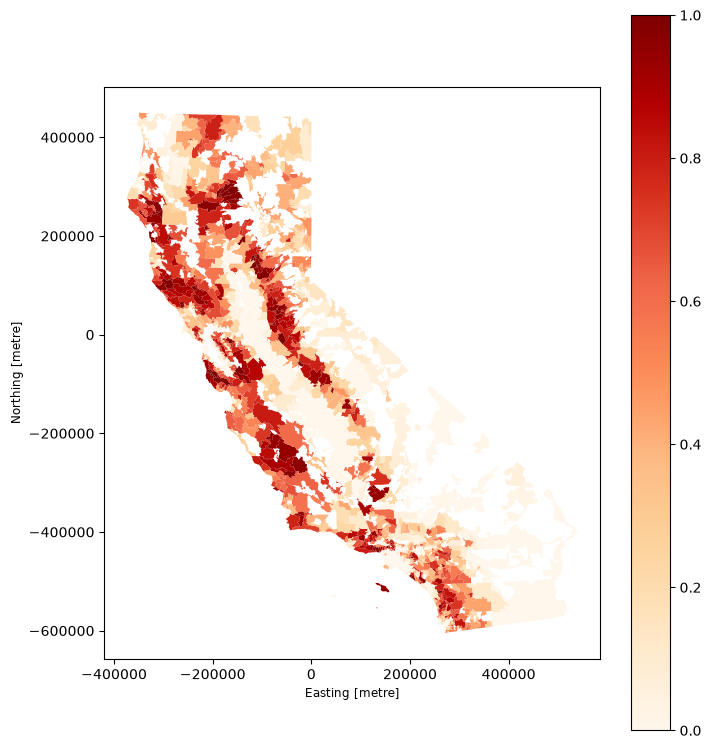

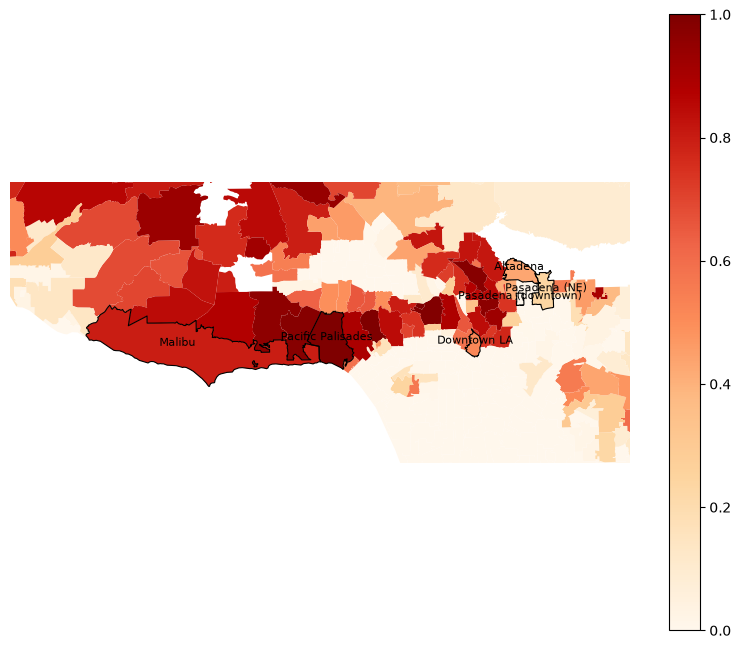

In [15]:
#plot to check: pad = 15 km of margin around the spot-check ZIPs

m = zips.merge(share[["zip", "share_high_or_vh"]], on = "zip")

#statewide
m.plot(column = "share_high_or_vh", cmap = "OrRd", legend = True, figsize = (8, 10))

#LA close-up with spot-check ZIPs outlined and labeled
la_zips = ["90265", "90272", "90012", "91001", "91101", "91107"]
spots = m[m["zip"].isin(la_zips)]

ax = m.plot(column = "share_high_or_vh", cmap = "OrRd", legend = True, figsize = (10, 8))
spots.boundary.plot(ax = ax, color = "black", linewidth = 0.8)

for _, row in spots.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(check_zips[row["zip"]], xy = (pt.x, pt.y), ha = "center", fontsize = 8)

xmin, ymin, xmax, ymax = spots.total_bounds
pad = 15000
ax.set_xlim(xmin - pad, xmax + pad)
ax.set_ylim(ymin - pad, ymax + pad)
ax.set_axis_off()

In [16]:
#save
share[["zip", "share_high", "share_very_high", "share_high_or_vh"]].to_csv(clean / "zip_fire_hazard_share.csv", index = False)

The spot checks matched our expectations, except Downtown LA (90012) was unusually high. We see that the ZIP covers Elysian Park and the hills around Dodger Stadium, which LA rates Very High. This reveals one of the limitations of our measure: it's the share of the land, not the share of the homes. We also see that in 90012, where the hazard land is a park where no one resides. 